In [17]:
import pickle, math
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

In [11]:
datafile_path = "./taskdata/task_statistics_2023-01-01-15-20-08.pkl"
data = pickle.load(open(datafile_path, "rb"))

In [14]:
def task_scatter(task_statistics, datafile='taskdata.pkl'):
    """
    Use matlibplot to draw a scatter plot of the finished time of each task, X-axis is the timeline, Y-axis is the finished time.
    Finished task is marked as blue circle, missing deadline task is marked as red x.
    task_statistics: defaultdict(TaskFinishedObject), each dict contains the information of a task
    dict_values([{'taskid': 'Period[0]_#39_Id[1]', 'release_time': 0.9750000000000001, 'deadline': 0.9850000000000001, 'priority': 1, 'dependency': [], 'res': 'success', 'start_time': '0.9760010242462158', 'end_time': '0.9840006828308105'}])
    """
    handlerid2color = ["_","blue","red","orange","purple","black","cyan","magenta"]
    handler2points = defaultdict(dict)
    for handler_id in range(1,5):
        handler2points[handler_id] = {
            'finished_x': [],
            'finished_y': [],
            'missing_x': [],
            'missing_y': [],
            'skip_x': [],
            'skip_y': []
        }

    # Iterate over the task statistics dictionary
    for task, task_info in task_statistics.items():
        handler_id = task_info["handler_id"]
        # If the task was finished on time, add its start time and end time to the finished lists
        if task_info['res'] == 'success':
            end_time = float(task_info['end_time'])
            release_time = float(task_info['release_time'])
            handler2points[handler_id]["finished_x"].append(end_time)
            handler2points[handler_id]["finished_y"].append(end_time - release_time)
        # If the task missed its deadline, add its release time and deadline to the missed lists
        elif task_info['res'] == 'failure':
            end_time = float(task_info['end_time'])
            release_time = float(task_info['release_time'])
            handler2points[handler_id]["missing_x"].append(end_time)
            handler2points[handler_id]["missing_y"].append(end_time - release_time)
        elif task_info["res"] == "skip":
            release_time = float(task_info['release_time'])
            handler2points[handler_id]["skip_x"].append(release_time)
            handler2points[handler_id]["skip_y"].append(0)
    
    # Create a figure and axis object using Matplotlib
    fig, ax = plt.subplots()
    handles = []
    for handler_id in [1,2,3,4]:
        if(len(handler2points[handler_id]["finished_x"]) == 0 and len(handler2points[handler_id]["missing_x"]) == 0 and len(handler2points[handler_id]["skip_x"]) == 0):
            continue
        # Plot the finished tasks as blue circles
        finished_scatter = ax.scatter(handler2points[handler_id]["finished_x"], handler2points[handler_id]["finished_y"], c = handlerid2color[handler_id], marker='o', s = 15, label= f"{handler_id} Finished")
        ax.scatter(handler2points[handler_id]["missing_x"], handler2points[handler_id]["missing_y"], c = handlerid2color[handler_id], marker='x', s = 35, label= f"{handler_id} Missing")
        ax.scatter(handler2points[handler_id]["skip_x"], handler2points[handler_id]["skip_y"], c = handlerid2color[handler_id], marker='+', s = 35, label= f"{handler_id} Skipped") 
        missing_deadline_rate = len(handler2points[handler_id]["missing_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finished_rate = len(handler2points[handler_id]["finished_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        handles.append(finished_scatter)
    ax.legend(loc="best", title="Handler ID")
    # ax.legend(['o', 'x', '+'], ['Finished', 'Missed', 'Skip'], loc="upper right", title="Task Status")
    # Set the X and Y axis labels
    ax.set_xlabel('Timeline')
    ax.set_ylabel('Task Finished Time')
    ax.set_ylim(0, 0.05)
    plt.title("Dynamic Workloads Tasks Pipeline")
    
    # Show the plot
    plt.show()

    # plt.savefig(f'./taskdata_figure/{datafile}.pdf') 

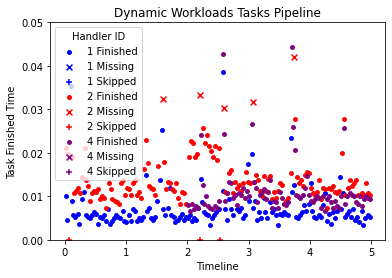

In [15]:
task_scatter(data)

In [25]:
datafile_path = "./taskdata/task_statistics_2023-01-03-01-12-17.pkl"
data = pickle.load(open(datafile_path, "rb"))


In [58]:
def task_boxplot(task_statistics, datafile='taskdata.pkl'):
    """
    Use matlibplot to draw a scatter plot of the finished time of each task, X-axis is the timeline, Y-axis is the finished time.
    Finished task is marked as blue circle, missing deadline task is marked as red x.
    task_statistics: defaultdict(TaskFinishedObject), each dict contains the information of a task
    dict_values([{'taskid': 'Period[0]_#39_Id[1]', 'release_time': 0.9750000000000001, 'deadline': 0.9850000000000001, 'priority': 1, 'dependency': [], 'res': 'success', 'start_time': '0.9760010242462158', 'end_time': '0.9840006828308105'}])
    """
    handlerid2color = ["_","blue","red","orange","purple","black","cyan","magenta"]
    handler2points = defaultdict(dict)
    handler2boxdata = defaultdict(dict)
    for handler_id in range(1,5):
        handler2points[handler_id] = {
            'finished_x': [],
            'finished_y': [],
            'missing_x': [],
            'missing_y': [],
            'skip_x': [],
            'skip_y': []
        }
        handler2boxdata[handler_id] = []

    # Iterate over the task statistics dictionary
    for task, task_info in task_statistics.items():
        handler_id = task_info["handler_id"]
        # If the task was finished on time, add its start time and end time to the finished lists
        release_time = float(task_info['release_time'])
        end_time = float(task_info['end_time'])
        if task_info['res'] == 'success':
            handler2points[handler_id]["finished_x"].append(end_time)
            handler2points[handler_id]["finished_y"].append(end_time - release_time)
        # If the task missed its deadline, add its release time and deadline to the missed lists
        elif task_info['res'] == 'failure':
            handler2points[handler_id]["missing_x"].append(end_time)
            handler2points[handler_id]["missing_y"].append(end_time - release_time)
        elif task_info["res"] == "skip":
            handler2points[handler_id]["skip_x"].append(release_time)
            handler2points[handler_id]["skip_y"].append(0)
        # box data group by release time per seconds
        if(math.floor(release_time) >= len(handler2boxdata[handler_id])):
            handler2boxdata[handler_id].append([])
        # 按release time每秒聚类
        handler2boxdata[handler_id][math.floor(release_time)].append(end_time - release_time)
    
    # print('handler box data', handler2boxdata)
    # Create a figure and axis object using Matplotlib
    fig, ax = plt.subplots()
    finish_handles = []
    missing_handles = []
    skip_handles = []

    for handler_id in [2]:
        if(len(handler2points[handler_id]["finished_x"]) == 0 and len(handler2points[handler_id]["missing_x"]) == 0 and len(handler2points[handler_id]["skip_x"]) == 0):
            continue
        # Plot the finished tasks as blue circles
        
        ax.boxplot(handler2boxdata[handler_id])
        # ax.set_xticklabels(range(1,len(handler2boxdata[handler_id])))

        missing_deadline_rate = len(handler2points[handler_id]["missing_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        finished_rate = len(handler2points[handler_id]["finished_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        skip_rate = len(handler2points[handler_id]["skip_x"]) / (len(handler2points[handler_id]["finished_x"]) + len(handler2points[handler_id]["missing_x"]) + len(handler2points[handler_id]["skip_x"]))
        print('Statistics of handler ', handler_id, ':')
        print('missing deadline rate: ', missing_deadline_rate)
        print('finished rate: ', finished_rate)
        print('skip rate: ', skip_rate)

    # ax.legend(loc="upper right", title="Handler ID")
    # ax.legend(['o', 'x', '+'], ['Finished', 'Missed', 'Skip'], loc="upper right", title="Task Status")
    # Set the X and Y axis labels
    ax.set_xlabel('Timeline')
    ax.set_ylabel('Task Response Time')
    # ax.set_ylim(0, 0.05)
    plt.title("Async Inference Tasks")
    
    # Show the plot
    plt.show()

    # plt.savefig(f'./taskdata_figure/{datafile}.pdf') 

Statistics of handler  2 :
missing deadline rate:  0.19393939393939394
finished rate:  0.6242424242424243
skip rate:  0.18181818181818182


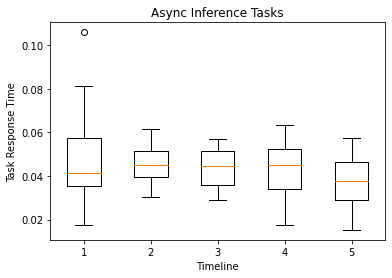

In [59]:
task_boxplot(data, 'Async Inference Tasks')

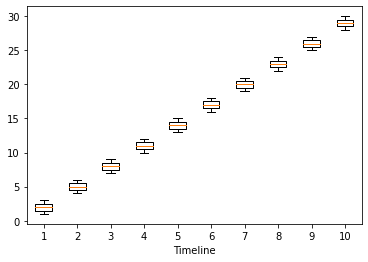

In [22]:
import matplotlib.pyplot as plt
# Create a list of lists, where each inner list represents the data for a given second
data = [[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12], [13, 14, 15], [16, 17, 18], [19, 20, 21], [22, 23, 24], [25, 26, 27], [28, 29, 30]]

# Create a figure and axis object using Matplotlib
fig, ax = plt.subplots()

# Plot the data as a boxplot
ax.boxplot(data)

# Set the X-axis labels to the seconds of time
ax.set_xticklabels(range(1, 11))

# Set the X-axis label to 'Timeline'
ax.set_xlabel('Timeline')

# Show the plot
plt.show()